# Notebook 1 of 2: data, labels and features

Flagging unanswerable visual questions with image-text fusion. Adelaide University, Multimodal Data Fusion, Project 2.2 (individual submission).

**What this notebook does**

1. Downloads VizWiz-VQA (Gurari et al. 2018) and the labelled test annotations (`VQA_test.json`), and builds the splits: **train = official train (20,523 pairs), dev = official validation (4,319), test = official test (8,000)**.
2. Builds the label (`y = 1` means unanswerable), the crowd vote share, and subgroup columns for the bias analysis: photo sharpness group, question frequency, answer type.
3. Characterises the data: class balance, label ambiguity, repeated questions, photo quality (Section 4, Figure `data_characterisation.png`).
4. Extracts frozen **ViT-B/16** image features, **BERT-base** question features and **CLIP** reference features once, and caches them on Google Drive with `meta.csv` and `manifest.json`.
5. Measures encoder latency on a T4 GPU.

Notebook 2 (`02_train_and_evaluate.ipynb`) trains and evaluates every model from the cached features.

**Run it:** Runtime > Change runtime type > **T4 GPU**, then Runtime > **Run all**, and allow Google Drive access. A first run downloads about 20 GB of photos and takes about 45 minutes. If the features are already cached on Drive, the photos are not downloaded and the run takes a few minutes.

The crowd answers decide the label, so they are used **only** to build labels and for data analysis, never as model inputs.

## 1. Setup

All settings live in `CONFIG`.

In [1]:
import os, sys, re, json, time, shutil, subprocess, hashlib
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from tqdm import tqdm as _tqdm

tqdm = partial(_tqdm, ascii=True, mininterval=5)  # plain-text progress bars (no notebook widgets)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

CONFIG = {
    # Storage: features, figures and results go to Google Drive; photos stay on the Colab disk
    "use_drive": True,
    "drive_dir": "/content/drive/MyDrive/vizwiz_fusion",
    "local_out_dir": "/content/vizwiz_fusion",
    "data_dir": "/content/data/vizwiz",
    "download": True,
    # Labelled test annotations (Annotations.zip has no test labels)
    "test_annotations_url": "https://vizwiz.cs.colorado.edu/VizWiz_all_answers/VQA_test.json",
    "test_annotations_path": None,   # None = download from the URL above into data_dir
    # Quick check: rows per split (stratified). None = use everything
    "n_per_split": None,
    "sample_seed": 42,
    # Frozen encoders
    "image_model": "google/vit-base-patch16-224-in21k",
    "text_model": "bert-base-uncased",
    "use_clip": True,
    "clip_model": "openai/clip-vit-base-patch32",
    "image_size": 224,
    "image_token_grid": 7,           # 14x14 ViT patch tokens average-pooled to 7x7 = 49 region tokens
    "max_q_tokens": 40,
    "extract_batch_size": 64,
    "num_workers": 2,
    # Subgroups
    "rare_question_max_count": 1,    # rare question = seen at most this many times in train
    # Speed check
    "latency_runs": 50,
}

In [2]:
import torch

IN_COLAB = "google.colab" in sys.modules
if CONFIG["use_drive"] and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path(CONFIG["drive_dir"])
else:
    OUT = Path(CONFIG["local_out_dir"])

FEAT_DIR, FIG_DIR, RES_DIR = OUT / "features", OUT / "figures", OUT / "results"
DATA = Path(CONFIG["data_dir"])
for d in (FEAT_DIR, FIG_DIR, RES_DIR, DATA):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FEAS = {"device": DEVICE}
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    FEAS.update(gpu=props.name, gpu_vram_gb=round(props.total_memory / 1e9, 1))
    print(f"GPU: {props.name} ({FEAS['gpu_vram_gb']} GB)")
else:
    print("No GPU found. Use Runtime > Change runtime type > T4 GPU, then run again.")
print("Outputs ->", OUT)

Mounted at /content/drive
GPU: Tesla T4 (15.6 GB)
Outputs -> /content/drive/MyDrive/vizwiz_fusion


## 2. Annotations and test labels

`Annotations.zip` holds train, validation and test questions, but the test file has no labels. The labelled test file is `VQA_test.json` from the VizWiz "all answers" release. The notebook checks that every test pair gets an `answerable` value; if not, it stops before training.

In [3]:
import requests

BASE_URL = "https://vizwiz.cs.colorado.edu/VizWiz_final"
IMAGE_ZIPS = {s: f"{BASE_URL}/images/{s}.zip" for s in ("train", "val", "test")}
DOWNLOAD_LOG = RES_DIR / "download_log.json"


def download(url, path, chunk=8 * 1024 * 1024):
    # Stream to disk with a progress bar; resume a partial file if the server allows it
    done = path.stat().st_size if path.exists() else 0
    headers = {"Range": f"bytes={done}-"} if done else {}
    with requests.get(url, stream=True, headers=headers, timeout=60) as r:
        if done and r.status_code != 206:
            done = 0
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) + done
        with open(path, "ab" if done else "wb") as f, tqdm(total=total, initial=done, unit="B",
                                                          unit_scale=True, desc=path.name) as bar:
            for block in r.iter_content(chunk):
                f.write(block)
                bar.update(len(block))


def download_and_extract(name, url, dest):
    marker = dest / f".{name}.done"
    if marker.exists():
        print(f"{name}: already done, skipping")
        return
    print(f"{name}: {shutil.disk_usage(dest).free / 1e9:.0f} GB free on local disk")
    zpath, t0 = dest / name, time.time()
    download(url, zpath)
    size_gb, t1 = zpath.stat().st_size / 1e9, time.time()
    subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)], check=True)
    zpath.unlink()
    marker.touch()
    log = json.loads(DOWNLOAD_LOG.read_text()) if DOWNLOAD_LOG.exists() else {}
    log[name] = {"size_gb": round(size_gb, 2), "download_min": round((t1 - t0) / 60, 1),
                 "unzip_min": round((time.time() - t1) / 60, 1)}
    DOWNLOAD_LOG.write_text(json.dumps(log, indent=2))
    print(f"{name}: {size_gb:.2f} GB, downloaded in {(t1 - t0) / 60:.1f} min")


if CONFIG["download"]:
    download_and_extract("Annotations.zip", f"{BASE_URL}/vqa_data/Annotations.zip", DATA)

TEST_LABELS = Path(CONFIG["test_annotations_path"] or DATA / "VQA_test.json")
if not TEST_LABELS.exists() and CONFIG["test_annotations_url"]:
    download(CONFIG["test_annotations_url"], TEST_LABELS)
print("Labelled test file:", TEST_LABELS if TEST_LABELS.exists() else "NOT FOUND")

Annotations.zip: 121 GB free on local disk


Annotations.zip: 100%|##########| 1.71M/1.71M [00:00<00:00, 12.2MB/s]


Annotations.zip: 0.00 GB, downloaded in 0.0 min


VQA_test.json: 100%|##########| 8.23M/8.23M [00:00<00:00, 37.4MB/s]

Labelled test file: /content/data/vizwiz/VQA_test.json


## 3. Labels, subgroups and splits

- **Label** `y = 1 - answerable` (1 = unanswerable). All main models use this hard label (`data.label: hard` in the repo config).
- **`unans_votes`**: how many of the 10 crowd answers say "unanswerable" or "unsuitable". `src/data.py` builds the soft label from it (vote share) for the ablation in section 7.
- **Question frequency**: how often the normalised question appears in **train**. A question is **rare** if it was seen at most once in train.

The feature fingerprint depends only on the image names and questions, in order. Adding the test labels does not change it, so the cached features are reused.

In [4]:
UNANS_VOTES = {"unanswerable", "unsuitable", "unsuitable image"}
SPLIT_NAMES = {"train": "train", "val": "dev", "test": "test"}
ORDER = {"train": 0, "dev": 1, "test": 2}


def find_one(root, filename):
    hits = sorted(p for p in Path(root).rglob(filename) if "__MACOSX" not in p.parts)
    if not hits:
        raise FileNotFoundError(f"{filename} not found under {root}. Did the Annotations.zip download finish?")
    return hits[0]


def load_split(json_path, official):
    with open(json_path) as f:
        records = json.load(f)
    if not isinstance(records, list):
        raise ValueError(f"{json_path} should hold a list of records, found {type(records).__name__}")
    rows = [{"image": r["image"],
             "question": str(r.get("question", "")).strip(),
             "answers": [str(a.get("answer", "")).strip().lower() for a in (r.get("answers") or [])],
             "answer_type": r.get("answer_type"),
             "answerable": r.get("answerable"),
             "official_split": official,
             "split": SPLIT_NAMES[official]} for r in records]
    print(f"{json_path.name}: {len(rows):,} records; fields: {sorted(records[0].keys())}")
    return pd.DataFrame(rows)


def split_index(df):
    return {s: np.where(df["split"].values == s)[0] for s in ORDER}


raw = pd.concat([load_split(find_one(DATA, f"{s}.json"), s) for s in ("train", "val", "test")], ignore_index=True)

# Test labels from VQA_test.json, matched by image name
if TEST_LABELS.exists():
    ext = load_split(TEST_LABELS, "test").drop_duplicates("image").set_index("image")
    is_test = (raw["split"] == "test").values
    n_match = int(raw.loc[is_test, "image"].isin(ext.index).sum())
    q_same = (raw.loc[is_test, "image"].map(ext["question"]) == raw.loc[is_test, "question"]).mean()
    print(f"Test pairs matched in {TEST_LABELS.name}: {n_match:,} of {int(is_test.sum()):,}; "
          f"same question text: {q_same:.1%}")
    raw.loc[is_test, "answerable"] = raw.loc[is_test, "image"].map(ext["answerable"]).values
    raw.loc[is_test, "answer_type"] = raw.loc[is_test, "image"].map(ext["answer_type"]).values
    ext_answers = ext["answers"].to_dict()
    raw["answers"] = [ext_answers.get(im, a) if t else a for im, a, t in zip(raw["image"], raw["answers"], is_test)]

raw["y"] = 1.0 - pd.to_numeric(raw["answerable"], errors="coerce")
n_test = int((raw.split == "test").sum())
n_test_lab = int(raw.loc[raw.split == "test", "y"].notna().sum())
HAS_TEST_LABELS = n_test > 0 and n_test_lab == n_test
print(f"Test pairs with an 'answerable' label: {n_test_lab:,} of {n_test:,}")
if not HAS_TEST_LABELS:
    print("WARNING: not every test pair has a label. Check VQA_test.json (it needs an 'answerable' field).\n"
          "Features and data analysis still run; training stops in section 6.")

raw["n_answers"] = raw["answers"].str.len()
raw["unans_votes"] = raw["answers"].apply(lambda a: sum(x in UNANS_VOTES for x in a))
raw["vote_share"] = np.where(raw["n_answers"] > 0, raw["unans_votes"] / raw["n_answers"].clip(lower=1), np.nan)


def norm_q(q):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]+", " ", q.lower())).strip()


raw["q_norm"] = raw["question"].map(norm_q)
train_counts = raw.loc[raw.split == "train", "q_norm"].value_counts()
raw["q_freq_train"] = raw["q_norm"].map(train_counts).fillna(0).astype(int)
raw["rare_question"] = raw["q_freq_train"] <= CONFIG["rare_question_max_count"]
raw["q_words"] = raw["question"].str.split().str.len()


def take(df, n, seed):
    # Optional small stratified sample for a quick check
    if n is None or n >= len(df):
        return df
    if df["y"].notna().all():
        return pd.concat([g.sample(max(1, round(n * len(g) / len(df))), random_state=seed)
                          for _, g in df.groupby("y")])
    return df.sample(n, random_state=seed)


def finalise(df):
    df = df.sort_values("split", key=lambda s: s.map(ORDER), kind="stable").reset_index(drop=True)
    df["row"] = np.arange(len(df))
    fp = hashlib.md5("|".join(df["image"] + "#" + df["question"]).encode()).hexdigest()[:12]
    return df, split_index(df), fp


meta = pd.concat([take(raw[raw.split == s], CONFIG["n_per_split"], CONFIG["sample_seed"]) for s in ORDER],
                 ignore_index=True)
meta, IDX, FINGERPRINT = finalise(meta)
display(meta.groupby("split", sort=False)["y"].agg(pairs="size", labelled="count", unanswerable_rate="mean").round(3))
print("Feature fingerprint:", FINGERPRINT)

train.json: 20,523 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
val.json: 4,319 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
test.json: 8,000 records; fields: ['image', 'question']
VQA_test.json: 8,000 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
Test pairs matched in VQA_test.json: 8,000 of 8,000; same question text: 100.0%
Test pairs with an 'answerable' label: 8,000 of 8,000


,pairs,labelled,unanswerable_rate
split,,,
train,20523,20523,0.270
dev,4319,4319,0.321
test,8000,8000,0.268


Feature fingerprint: 895f3ed603bb


### Photos: download only if something still has to be computed from them

Photos are needed only for feature extraction, the photo-quality measures and the latency test. If all three are already cached for this fingerprint, nothing is downloaded.

In [5]:
GROUPS = {"vit": ["img_cls", "img_tok", "img_ok"],
          "bert": ["txt_cls", "txt_mean", "txt_tok", "txt_mask"],
          "clip": ["clip_img", "clip_txt"]}
fpath = lambda name: FEAT_DIR / f"{name}_{FINGERPRINT}.npy"
have = lambda group: all(fpath(n).exists() for n in GROUPS[group])
QUAL_PATH = RES_DIR / f"image_quality_{FINGERPRINT}.csv"
LATENCY_PATH = RES_DIR / "encoder_latency.json"

# Latency from an earlier run of this notebook (older runs kept it inside baselines_summary.json)
OLD_SUMMARY = RES_DIR / "baselines_summary.json"
if not LATENCY_PATH.exists() and OLD_SUMMARY.exists():
    old_lat = json.loads(OLD_SUMMARY.read_text()).get("feasibility", {}).get("encoder_latency")
    if old_lat:
        LATENCY_PATH.write_text(json.dumps(old_lat, indent=2))

needed = {"features": not (have("vit") and have("bert") and (have("clip") or not CONFIG["use_clip"])),
          "photo quality": not QUAL_PATH.exists(), "latency": not LATENCY_PATH.exists()}
NEED_IMAGES = any(needed.values())
print("Still to compute from photos:", [k for k, v in needed.items() if v] or "nothing (photos not needed)")

if NEED_IMAGES:
    if CONFIG["download"]:
        for s, url in IMAGE_ZIPS.items():
            download_and_extract(f"{s}.zip", url, DATA)
    img_index = {}
    for dirpath, _, files in os.walk(DATA, followlinks=True):
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                img_index[f] = os.path.join(dirpath, f)
    meta["path"] = meta["image"].map(img_index)
    missing = int(meta["path"].isna().sum())
    print(f"Photos found: {len(img_index):,}; pairs without a photo: {missing}")
    if missing == len(meta):
        raise RuntimeError(f"No photos found under {DATA}. Check that the image zips finished unzipping.")
    if missing:
        meta, IDX, FINGERPRINT = finalise(meta.dropna(subset=["path"]))
        print("Pairs without a photo were dropped; new fingerprint:", FINGERPRINT)
PATHS = meta["path"].tolist() if "path" in meta else None
QUESTIONS = meta["question"].tolist()

Still to compute from photos: nothing (photos not needed)


## 4. Data characterisation

Photo sharpness is the variance of the Laplacian, a standard focus measure (Pech-Pacheco et al. 2000), computed for **every** photo (not a sample), so each pair can be put in a sharpness group: **blurry / medium / sharp**, cut at the train tertiles. Sharpness is compared between answerable and unanswerable photos with a two-sided Mann-Whitney U test (Mann & Whitney 1947). The result is cached, so this only runs once. Choices (sharpness cut points, rare-question counts) use train only; test is only described here, never used for tuning.

In [6]:
from multiprocessing import Pool
from PIL import Image, ImageOps
from scipy.stats import mannwhitneyu


def image_quality(path, size=256):
    try:
        with Image.open(path) as im:
            w, h = im.size
            im.draft("L", (size, size))  # fast reduced-size JPEG decode
            g = np.asarray(ImageOps.exif_transpose(im).convert("L").resize((size, size)), dtype=np.float32)
        lap = g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:] - 4 * g[1:-1, 1:-1]
        return w, h, os.path.getsize(path) / 1024, float(lap.var()), float(g.mean()), 1
    except Exception:
        return np.nan, np.nan, np.nan, np.nan, np.nan, 0


QUAL_COLS = ["width", "height", "file_kb", "sharpness", "brightness", "readable"]
QUAL_PATH = RES_DIR / f"image_quality_{FINGERPRINT}.csv"
if QUAL_PATH.exists():
    qual = pd.read_csv(QUAL_PATH)
    print("Loaded cached photo quality")
else:
    with Pool(max(1, os.cpu_count() or 1)) as pool:
        qual = pd.DataFrame(list(tqdm(pool.imap(image_quality, meta["path"], chunksize=64),
                                      total=len(meta), desc="photo quality")), columns=QUAL_COLS)
    qual.insert(0, "image", meta["image"].values)
    qual.to_csv(QUAL_PATH, index=False)
assert (qual["image"].values == meta["image"].values).all()
for c in QUAL_COLS:
    meta[c] = qual[c].values
meta["megapixels"] = meta["width"] * meta["height"] / 1e6

# Sharpness groups cut at the train tertiles
tr_sharp = meta.loc[IDX["train"], "sharpness"].dropna()
cuts = np.quantile(tr_sharp, [1 / 3, 2 / 3])
meta["sharp_bin"] = pd.cut(meta["sharpness"].fillna(tr_sharp.median()), [-np.inf, cuts[0], cuts[1], np.inf],
                           labels=["blurry", "medium", "sharp"]).astype(str)
print(f"Unreadable photos: {int((meta['readable'] == 0).sum())}; sharpness cuts at {cuts.round(1)}")

Loaded cached photo quality
Unreadable photos: 0; sharpness cuts at [153.5 485.1]


In [7]:
LAB = {0: "answerable", 1: "unanswerable"}
tr = meta.loc[IDX["train"]]
lab = meta[meta["y"].notna()]
top_q = (tr.groupby("q_norm")["y"].agg(count="size", unanswerable_rate="mean")
         .sort_values("count", ascending=False).head(10).round(3))
mw = mannwhitneyu(tr.loc[tr.y == 0, "sharpness"].dropna(), tr.loc[tr.y == 1, "sharpness"].dropna())

STATS = {
    "n_pairs_by_split": {s: int(len(IDX[s])) for s in IDX},
    "unanswerable_rate_by_split": lab.groupby("split")["y"].mean().round(3).to_dict(),
    "ambiguous_answerable_share_train": round(float(((tr.y == 0) & (tr.unans_votes >= 3)).mean()), 3),
    "ambiguous_share_of_answerable_train": round(float((tr.loc[tr.y == 0, "unans_votes"] >= 3).mean()), 3),
    "repeated_question_share_train": round(float((tr.q_freq_train >= 2).mean()), 3),
    # Same definition as the pilot and proposal (exact lower-case text, train + dev): 57.6% in the pilot
    "duplicate_questions_share_pilot_def": round(float(
        meta.loc[np.r_[IDX["train"], IDX["dev"]], "question"].str.lower().duplicated(keep=False).mean()), 3),
    "rare_question_share_by_split": meta.groupby("split")["rare_question"].mean().round(3).to_dict(),
    "unseen_question_share_test": round(float((meta.loc[IDX["test"], "q_freq_train"] == 0).mean()), 3),
    "question_words_median": float(meta["q_words"].median()),
    "sharpness_median_by_label_train": {LAB[int(k)]: v for k, v in tr.groupby("y")["sharpness"].median().round(1).items()},
    "sharpness_mannwhitney_p_train": float(mw.pvalue),
    "unanswerable_rate_by_sharp_bin_train": tr.groupby("sharp_bin")["y"].mean().round(3).to_dict(),
    "unreadable_photos": int((meta["readable"] == 0).sum()),
    "top_questions_train": top_q.reset_index().to_dict(orient="records"),
}

# The proposal's findings table, recomputed on the full data
r = STATS["unanswerable_rate_by_split"]
findings = pd.DataFrame([
    ["Unanswerable share by split", ", ".join(f"{k} {v:.1%}" for k, v in r.items()),
     "Weighted loss (pos_weight) and dev-tuned threshold"],
    ["Answerable pairs with >= 3/10 'unanswerable' votes (train)", f"{STATS['ambiguous_answerable_share_train']:.1%} of pairs",
     "Hard labels for main models; soft-label ablation"],
    ["Train pairs whose question repeats in train", f"{STATS['repeated_question_share_train']:.1%}",
     "Question-only baseline; rare-question subset"],
    ["Test questions rare in train (<= 1 time)", f"{STATS['rare_question_share_by_split'].get('test', float('nan')):.1%}",
     "Report rare vs common results"],
    ["Sharpness, answerable vs unanswerable (train median)",
     f"{STATS['sharpness_median_by_label_train']} (p = {STATS['sharpness_mannwhitney_p_train']:.1e})",
     "Sharpness-stratified evaluation; photo-quality baseline"],
], columns=["Finding", "Value", "Mitigation"])
display(findings)
print("\nMost frequent train questions:")
display(top_q)

,Finding,Value,Mitigation
0,Unanswerable share by split,"dev 32.1%, test 26.8%, train 27.0%",Weighted loss (pos_weight) and dev-tuned thres...
1,Answerable pairs with >= 3/10 'unanswerable' v...,12.2% of pairs,Hard labels for main models; soft-label ablation
2,Train pairs whose question repeats in train,59.4%,Question-only baseline; rare-question subset
3,Test questions rare in train (<= 1 time),46.2%,Report rare vs common results
4,"Sharpness, answerable vs unanswerable (train m...","{'answerable': 347.5, 'unanswerable': 155.8} (...",Sharpness-stratified evaluation; photo-quality...



Most frequent train questions:


,count,unanswerable_rate
q_norm,,
what is this,3078,0.115
what color is this,425,0.019
what is it,298,0.094
what is this item,270,0.130
what does this say,226,0.341
what color is this shirt,209,0.062
what s this,182,0.154
what is that,170,0.076
what is in this box,167,0.102


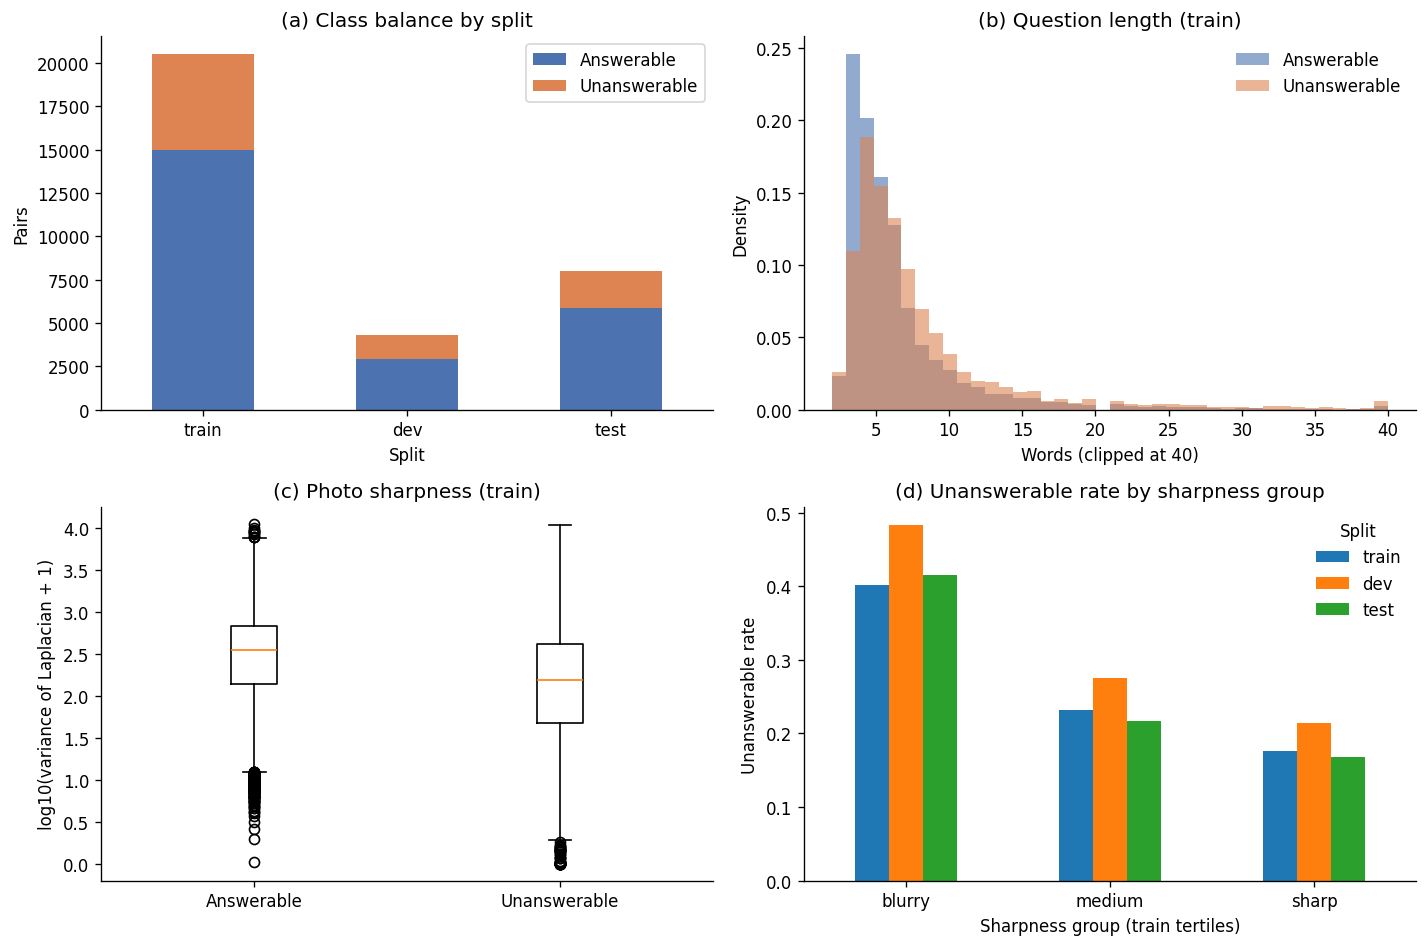

In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {0: "Answerable", 1: "Unanswerable"}
COLOURS = {0: "#4C72B0", 1: "#DD8452"}
splits = [s for s in ("train", "dev", "test") if len(IDX[s])]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
counts = lab.groupby(["split", "y"]).size().unstack().reindex([s for s in splits if s in lab.split.values])
counts.columns = [LABELS[int(c)] for c in counts.columns]
counts.plot(kind="bar", stacked=True, ax=ax, color=[COLOURS[0], COLOURS[1]], rot=0)
ax.set(title="(a) Class balance by split", xlabel="Split", ylabel="Pairs")

ax = axes[0, 1]
for y in (0, 1):
    ax.hist(tr.loc[tr.y == y, "q_words"].clip(upper=40), bins=40, alpha=0.6, density=True,
            label=LABELS[y], color=COLOURS[y])
ax.set(title="(b) Question length (train)", xlabel="Words (clipped at 40)", ylabel="Density")
ax.legend(frameon=False)

ax = axes[1, 0]
ax.boxplot([np.log10(tr.loc[tr.y == y, "sharpness"].dropna() + 1) for y in (0, 1)])
ax.set_xticks([1, 2], [LABELS[0], LABELS[1]])
ax.set(title="(c) Photo sharpness (train)", ylabel="log10(variance of Laplacian + 1)")

ax = axes[1, 1]
rate = lab.groupby(["sharp_bin", "split"])["y"].mean().unstack().reindex(["blurry", "medium", "sharp"])
rate = rate[[s for s in splits if s in rate.columns]]
rate.plot(kind="bar", ax=ax, rot=0)
ax.set(title="(d) Unanswerable rate by sharpness group", xlabel="Sharpness group (train tertiles)",
       ylabel="Unanswerable rate")
ax.legend(title="Split", frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "data_characterisation.png", bbox_inches="tight")
plt.show()

## 5. Frozen feature extraction

Each encoder runs once and its output is saved to Drive straight away, so a Colab disconnect only loses the encoder that was running. If the features are cached, this section only loads them. Freezing pretrained encoders suits about 20,000 training pairs, which is too few to train them from scratch.

| Name | Shape | What it is |
|---|---|---|
| `img_cls` | N x 768 | ViT-B/16 [CLS] vector (Dosovitskiy et al. 2021) |
| `img_tok` | N x 49 x 768 | 14x14 patch tokens pooled to 7x7 region tokens (for cross-attention) |
| `img_ok` | N | 1 = photo read fine, 0 = unreadable (zero input) |
| `txt_cls`, `txt_mean` | N x 768 | BERT-base [CLS] and mask-aware mean (Devlin et al. 2019) |
| `txt_tok`, `txt_mask` | N x 40 x 768, N x 40 | BERT word tokens and padding mask (for cross-attention) |
| `clip_img`, `clip_txt` | N x 512 | CLIP ViT-B/32 image and text embeddings (Radford et al. 2021), reference only |

Photos get EXIF rotation and an **uncropped** 224x224 resize, because questions often ask about text near the edge of the frame. Row i of every array is row i of `meta.csv`.

In [9]:
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import AutoImageProcessor, AutoModel, AutoTokenizer

DESCRIPTIONS = {
    "img_cls": "ViT-B/16 [CLS] vector", "img_tok": "ViT-B/16 7x7 region tokens", "img_ok": "1 = photo readable",
    "txt_cls": "BERT [CLS] vector", "txt_mean": "BERT mask-aware mean", "txt_tok": "BERT word tokens",
    "txt_mask": "BERT padding mask (1 = real token)", "clip_img": "CLIP image embedding",
    "clip_txt": "CLIP text embedding"}
EXTRACTION_LOG = FEAT_DIR / f"extraction_log_{FINGERPRINT}.json"
if EXTRACTION_LOG.exists():
    FEAS.update(json.loads(EXTRACTION_LOG.read_text()))


def autocast():
    return torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda"))


def reset_peak():
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()


def peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None


def log_step(key, value):
    FEAS[key] = value
    keep = {k: FEAS[k] for k in FEAS if k.endswith("_extraction")}
    EXTRACTION_LOG.write_text(json.dumps(keep, indent=2))


def as_embedding(out):
    # transformers 4.x returns a tensor here, 5.x returns an output object
    return out if torch.is_tensor(out) else out.pooler_output


class PhotoDataset(Dataset):
    def __init__(self, paths, size, mean, std):
        self.paths, self.size = list(paths), size
        self.mean = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as im:
                im.draft("RGB", (self.size, self.size))
                im = ImageOps.exif_transpose(im).convert("RGB").resize((self.size, self.size),
                                                                     Image.Resampling.BICUBIC)
            x = torch.from_numpy(np.asarray(im, dtype=np.float32) / 255.0).permute(2, 0, 1)
            return (x - self.mean) / self.std, 1
        except Exception:
            return torch.zeros(3, self.size, self.size), 0


def photo_loader(paths, mean, std):
    return DataLoader(PhotoDataset(paths, CONFIG["image_size"], mean, std), batch_size=CONFIG["extract_batch_size"],
                      num_workers=CONFIG["num_workers"], pin_memory=(DEVICE == "cuda"))


@torch.no_grad()
def extract_vit(paths):
    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    model = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    n, g, d = len(paths), CONFIG["image_token_grid"], model.config.hidden_size
    cls, tok, ok = np.empty((n, d), np.float16), np.empty((n, g * g, d), np.float16), np.empty(n, np.uint8)
    reset_peak()
    t0, i = time.time(), 0
    for x, flag in tqdm(photo_loader(paths, proc.image_mean, proc.image_std), desc="ViT features"):
        x = x.to(DEVICE, non_blocking=True)
        with autocast():
            h = model(pixel_values=x).last_hidden_state
        b, side = len(x), int(round((h.shape[1] - 1) ** 0.5))
        grid = h[:, 1:].float().reshape(b, side, side, d).permute(0, 3, 1, 2)
        regions = F.adaptive_avg_pool2d(grid, g).flatten(2).transpose(1, 2)
        cls[i:i + b], tok[i:i + b], ok[i:i + b] = h[:, 0].float().cpu().numpy(), regions.cpu().numpy(), flag.numpy()
        i += b
    secs = time.time() - t0
    log_step("image_extraction", {"n": n, "minutes": round(secs / 60, 1), "images_per_sec": round(n / secs, 1),
                                  "peak_vram_gb": peak_gb(), "unreadable_images": int((ok == 0).sum())})
    return {"img_cls": cls, "img_tok": tok, "img_ok": ok}


@torch.no_grad()
def extract_bert(questions):
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model"])
    model = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    n, L, d, bs = len(questions), CONFIG["max_q_tokens"], model.config.hidden_size, 2 * CONFIG["extract_batch_size"]
    cls, mean = np.empty((n, d), np.float16), np.empty((n, d), np.float16)
    tok, mask = np.empty((n, L, d), np.float16), np.empty((n, L), np.uint8)
    full_len = np.array([len(t) for t in tokenizer(questions)["input_ids"]])
    reset_peak()
    t0 = time.time()
    for i in tqdm(range(0, n, bs), desc="BERT features"):
        enc = tokenizer(questions[i:i + bs], padding="max_length", truncation=True, max_length=L,
                        return_tensors="pt").to(DEVICE)
        with autocast():
            h = model(**enc).last_hidden_state
        h, m = h.float(), enc["attention_mask"].unsqueeze(-1).float()
        cls[i:i + bs] = h[:, 0].cpu().numpy()
        mean[i:i + bs] = ((h * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy()
        tok[i:i + bs], mask[i:i + bs] = h.cpu().numpy(), enc["attention_mask"].cpu().numpy()
    log_step("text_extraction", {"n": n, "minutes": round((time.time() - t0) / 60, 1), "peak_vram_gb": peak_gb(),
                                 "truncated_share": round(float((full_len > L).mean()), 4)})
    return {"txt_cls": cls, "txt_mean": mean, "txt_tok": tok, "txt_mask": mask}


@torch.no_grad()
def extract_clip(paths, questions):
    from transformers import CLIPModel
    proc = AutoImageProcessor.from_pretrained(CONFIG["clip_model"])
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["clip_model"])
    model = CLIPModel.from_pretrained(CONFIG["clip_model"]).to(DEVICE).eval()
    img, txt = [], []
    reset_peak()
    t0 = time.time()
    for x, _ in tqdm(photo_loader(paths, proc.image_mean, proc.image_std), desc="CLIP image"):
        with autocast():
            img.append(as_embedding(model.get_image_features(pixel_values=x.to(DEVICE))).float().cpu().numpy())
    bs = 2 * CONFIG["extract_batch_size"]
    for i in tqdm(range(0, len(questions), bs), desc="CLIP text"):
        enc = tokenizer(questions[i:i + bs], padding=True, truncation=True, max_length=77,
                        return_tensors="pt").to(DEVICE)
        with autocast():
            txt.append(as_embedding(model.get_text_features(**enc)).float().cpu().numpy())
    log_step("clip_extraction", {"n": len(paths), "minutes": round((time.time() - t0) / 60, 1),
                                 "peak_vram_gb": peak_gb()})
    return {"clip_img": np.concatenate(img).astype(np.float16), "clip_txt": np.concatenate(txt).astype(np.float16)}


def run_group(group, fn, *args):
    if have(group):
        print(f"{group}: cached")
        return
    arrays = fn(*args)
    for name, arr in arrays.items():
        np.save(fpath(name), arr)
    del arrays
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    print(f"{group}: saved")


run_group("vit", extract_vit, PATHS)
run_group("bert", extract_bert, QUESTIONS)
if CONFIG["use_clip"]:
    run_group("clip", extract_clip, PATHS, QUESTIONS)

vit: cached
bert: cached
clip: cached


### Hand-off files: `meta.csv` and `manifest.json`

`meta.csv` has one row per pair, in feature order. It has the columns required by `docs/data_contract.md` (`pair_id`, `question`, `official_split`, `y`, `unans_votes`) plus the subgroup columns for the bias part. It contains questions, so it stays on Drive and is **never committed** to GitHub.

In [10]:
meta["img_ok"] = np.load(fpath("img_ok"))
meta["pair_id"] = meta["image"]
assert meta["pair_id"].is_unique, "pair_id (image file name) must be unique"
META_COLS = ["pair_id", "question", "official_split", "y", "unans_votes", "row", "split", "vote_share",
             "answer_type", "q_norm", "q_words", "q_freq_train", "rare_question", "width", "height", "megapixels",
             "file_kb", "sharpness", "brightness", "sharp_bin", "readable", "img_ok"]
meta[META_COLS].to_csv(FEAT_DIR / "meta.csv", index=False)

feature_names = GROUPS["vit"] + GROUPS["bert"] + (GROUPS["clip"] if CONFIG["use_clip"] else [])
manifest = {
    "fingerprint": FINGERPRINT, "n_rows": int(len(meta)),
    "rows_by_split": {s: int(len(IDX[s])) for s in IDX}, "has_test_labels": HAS_TEST_LABELS,
    "test_labels_file": TEST_LABELS.name, "created": time.strftime("%Y-%m-%d %H:%M"),
    "encoders": {k: CONFIG[k] for k in ("image_model", "text_model", "clip_model", "image_size",
                                        "image_token_grid", "max_q_tokens")},
    "meta": "meta.csv", "features": {},
}
for n in feature_names:
    a = np.load(fpath(n), mmap_mode="r")
    manifest["features"][n] = {"file": fpath(n).name, "shape": list(a.shape), "dtype": str(a.dtype),
                               "description": DESCRIPTIONS[n]}
(FEAT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))
FEAS["features_on_disk_gb"] = round(sum(fpath(n).stat().st_size for n in feature_names) / 1e9, 2)
print(json.dumps({k: v for k, v in FEAS.items() if k.endswith("extraction") or k == "features_on_disk_gb"}, indent=2))

{
  "image_extraction": {
    "n": 32842,
    "minutes": 6.0,
    "images_per_sec": 90.8,
    "peak_vram_gb": 0.94,
    "unreadable_images": 0
  },
  "text_extraction": {
    "n": 32842,
    "minutes": 0.4,
    "peak_vram_gb": 0.78,
    "truncated_share": 0.0091
  },
  "clip_extraction": {
    "n": 32842,
    "minutes": 5.9,
    "peak_vram_gb": 0.95
  },
  "features_on_disk_gb": 4.71
}


### Encoder latency (one query, batch size 1)

The proposal sets a limit of 100 ms per query on a T4. The frozen encoders are almost all of that cost, so the encoder time is measured here: read and resize one photo, run ViT-B/16, tokenise and run BERT-base. The evaluation part adds the head time on top. The result is cached in `results/encoder_latency.json`.

In [11]:
@torch.no_grad()
def encoder_latency(n_runs):
    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    vit = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model"])
    bert = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    ds = PhotoDataset(PATHS, CONFIG["image_size"], proc.image_mean, proc.image_std)
    times = []
    for k in range(n_runs + 5):
        i = k % len(ds)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        x, _ = ds[i]
        enc = tokenizer([QUESTIONS[i]], truncation=True, max_length=CONFIG["max_q_tokens"],
                        return_tensors="pt").to(DEVICE)
        with autocast():
            vit(pixel_values=x.unsqueeze(0).to(DEVICE))
            bert(**enc)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        if k >= 5:  # first 5 runs are warm-up
            times.append((time.perf_counter() - t0) * 1000)
    del vit, bert
    return {"median_ms": round(float(np.median(times)), 1), "p95_ms": round(float(np.percentile(times, 95)), 1),
            "runs": n_runs, "device": FEAS.get("gpu", DEVICE)}


if LATENCY_PATH.exists():
    FEAS["encoder_latency"] = json.loads(LATENCY_PATH.read_text())
    print("Loaded cached latency")
else:
    FEAS["encoder_latency"] = encoder_latency(CONFIG["latency_runs"])
    LATENCY_PATH.write_text(json.dumps(FEAS["encoder_latency"], indent=2))
print(FEAS["encoder_latency"], "(target: <= 100 ms per query on a T4, including the fusion head)")

Loaded cached latency
{'median_ms': 37.3, 'p95_ms': 58.2, 'runs': 50, 'device': 'Tesla T4'} (target: <= 100 ms per query on a T4, including the fusion head)


## 6. Summary

Writes `results/data_summary.json` with every data number used in the report.

In [12]:
def to_py(o):
    return o.item() if hasattr(o, "item") else str(o)


if DOWNLOAD_LOG.exists():
    FEAS["downloads"] = json.loads(DOWNLOAD_LOG.read_text())
(RES_DIR / "data_summary.json").write_text(json.dumps(
    {"config": CONFIG, "fingerprint": FINGERPRINT, "has_test_labels": HAS_TEST_LABELS, "data": STATS,
     "feasibility": FEAS}, indent=2, default=to_py))
findings.to_csv(RES_DIR / "data_findings.csv", index=False)

r = STATS["unanswerable_rate_by_split"]
lat = FEAS.get("encoder_latency", {})
print("=== Data numbers for the report ===")
print(f"Pairs: train {len(IDX['train']):,} / dev {len(IDX['dev']):,} / test {len(IDX['test']):,}; "
      f"test labels for {n_test_lab:,} of {n_test:,}; unanswerable " + ", ".join(f"{k} {v:.1%}" for k, v in r.items()))
print(f"Label ambiguity: {STATS['ambiguous_answerable_share_train']:.1%} of train pairs are labelled answerable "
      f"with >= 3/10 'unanswerable' votes.")
print(f"Questions: {STATS['duplicate_questions_share_pilot_def']:.1%} of train + dev pairs repeat another pair's exact "
      f"question; {STATS['rare_question_share_by_split'].get('test', float('nan')):.1%} of test questions are rare in train.")
print(f"Photos: unanswerable rate blurry/medium/sharp (train) = {STATS['unanswerable_rate_by_sharp_bin_train']}; "
      f"Mann-Whitney p = {STATS['sharpness_mannwhitney_p_train']:.1e}; unreadable photos {STATS['unreadable_photos']}.")
print(f"Text: {FEAS.get('text_extraction', {}).get('truncated_share', float('nan')):.2%} of questions cut at "
      f"{CONFIG['max_q_tokens']} tokens.")
print(f"Features on disk {FEAS.get('features_on_disk_gb')} GB; encoders {lat.get('median_ms')} ms median per query "
      f"(p95 {lat.get('p95_ms')} ms) on {lat.get('device')}.")

=== Data numbers for the report ===
Pairs: train 20,523 / dev 4,319 / test 8,000; test labels for 8,000 of 8,000; unanswerable dev 32.1%, test 26.8%, train 27.0%
Label ambiguity: 12.2% of train pairs are labelled answerable with >= 3/10 'unanswerable' votes.
Questions: 57.6% of train + dev pairs repeat another pair's exact question; 46.2% of test questions are rare in train.
Photos: unanswerable rate blurry/medium/sharp (train) = {'blurry': 0.402, 'medium': 0.231, 'sharp': 0.176}; Mann-Whitney p = 1.1e-244; unreadable photos 0.
Text: 0.91% of questions cut at 40 tokens.
Features on disk 4.71 GB; encoders 37.3 ms median per query (p95 58.2 ms) on Tesla T4.


## 7. Save a clean copy for GitHub

Colab adds widget data to notebooks, which GitHub cannot display. After **Run all** has finished, this cell saves a clean copy of this notebook (outputs kept, widget data removed) to `notebook_for_github/` on Drive. Download that file and upload it to the repo.

In [13]:
def clean_notebook(nb):
    nb.get("metadata", {}).pop("widgets", None)
    for cell in nb.get("cells", []):
        outs = []
        for o in cell.get("outputs", []):
            data = o.get("data")
            if data is not None:
                data.pop("application/vnd.jupyter.widget-view+json", None)
                if not data:
                    continue
            outs.append(o)
        if "outputs" in cell:
            cell["outputs"] = outs
    return nb


try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
    dest = OUT / "notebook_for_github" / "01_data_and_features.ipynb"
    dest.parent.mkdir(exist_ok=True)
    dest.write_text(json.dumps(clean_notebook(nb), indent=1, ensure_ascii=True))
    print("Clean copy saved to", dest)
except Exception as e:
    print("Not in Colab (or the notebook could not be read), so no clean copy was saved:", type(e).__name__)

Clean copy saved to /content/drive/MyDrive/vizwiz_fusion/notebook_for_github/01_data_and_features.ipynb


## References

Devlin, J, Chang, M-W, Lee, K & Toutanova, K 2019, 'BERT: pre-training of deep bidirectional transformers for language understanding', in *Proceedings of the 2019 conference of the North American chapter of the Association for Computational Linguistics: human language technologies*, vol. 1, Association for Computational Linguistics, Minneapolis, USA, pp. 4171-4186.

Dosovitskiy, A, Beyer, L, Kolesnikov, A, Weissenborn, D, Zhai, X, Unterthiner, T, Dehghani, M, Minderer, M, Heigold, G, Gelly, S, Uszkoreit, J & Houlsby, N 2021, 'An image is worth 16x16 words: transformers for image recognition at scale', in *International conference on learning representations (ICLR 2021)*, online.

Gurari, D, Li, Q, Stangl, AJ, Guo, A, Lin, C, Grauman, K, Luo, J & Bigham, JP 2018, 'VizWiz grand challenge: answering visual questions from blind people', in *Proceedings of the IEEE conference on computer vision and pattern recognition (CVPR)*, IEEE, Salt Lake City, USA, pp. 3608-3617.

Mann, HB & Whitney, DR 1947, 'On a test of whether one of two random variables is stochastically larger than the other', *Annals of Mathematical Statistics*, vol. 18, no. 1, pp. 50-60.

Pech-Pacheco, JL, Cristobal, G, Chamorro-Martinez, J & Fernandez-Valdivia, J 2000, 'Diatom autofocusing in brightfield microscopy: a comparative study', in *Proceedings of the 15th international conference on pattern recognition (ICPR 2000)*, vol. 3, IEEE, Barcelona, Spain, pp. 314-317.

Radford, A, Kim, JW, Hallacy, C, Ramesh, A, Goh, G, Agarwal, S, Sastry, G, Askell, A, Mishkin, P, Clark, J, Krueger, G & Sutskever, I 2021, 'Learning transferable visual models from natural language supervision', in *Proceedings of the 38th international conference on machine learning (ICML 2021)*, PMLR, vol. 139, pp. 8748-8763.

VizWiz n.d., *Visual question answering*, VizWiz, viewed 26 October 2026, <https://vizwiz.org/tasks-and-datasets/vqa/>.